# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Notebook ini mengerjakan Simple Regression (`Ads_Data.csv`) dan Simple Classification (`Email_Data.csv`).

**Ketentuan:** implementasi model dan metrik utama dibuat manual menggunakan NumPy. Scikit-learn hanya digunakan pada bagian bonus.

**RANDOM_STATE:** 10 (dua digit terakhir NIM).

## Persiapan dan import library
Pastikan `Ads_Data.csv` dan `Email_Data.csv` berada satu folder dengan notebook ini.

In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_STATE = 10
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
plt.style.use("default")

ADS_PATH = Path("Ads_Data.csv")
EMAIL_PATH = Path("Email_Data.csv")

if not ADS_PATH.exists():
  raise FileNotFoundError(f"File tidak ditemukan: {ADS_PATH.resolve()}")
if not EMAIL_PATH.exists():
  raise FileNotFoundError(f"File tidak ditemukan: {EMAIL_PATH.resolve()}")

ads_df = pd.read_csv(ADS_PATH)
email_df = pd.read_csv(EMAIL_PATH)

print("Ads_Data.csv:", ads_df.shape)
display(ads_df.head())
print("Email_Data.csv:", email_df.shape)
display(email_df.head())

Ads_Data.csv: (40, 2)


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Email_Data.csv: (60, 3)


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


## Pemeriksaan data
Kolom yang diharapkan:
- Ads: `BiayaIklan`, `Penjualan`
- Email: `JumlahLink`, `KataPromo`, `Spam`

In [6]:
print("Kolom Ads:", ads_df.columns.tolist())
print("Kolom Email:", email_df.columns.tolist())
print("Tipe Ads:")
display(ads_df.dtypes.rename("dtype").to_frame())
print("Tipe Email:")
display(email_df.dtypes.rename("dtype").to_frame())
print("Missing Ads:")
display(ads_df.isna().sum().rename("jumlah").to_frame())
print("Missing Email:")
display(email_df.isna().sum().rename("jumlah").to_frame())
print("Duplikasi Ads:", int(ads_df.duplicated().sum()))
print("Duplikasi Email:", int(email_df.duplicated().sum()))
print("\nInfo Ads:")
display(ads_df.describe(include="all"))
print("\nInfo Email:")
display(email_df.describe(include="all"))

Kolom Ads: ['BiayaIklan', 'Penjualan']
Kolom Email: ['JumlahLink', 'KataPromo', 'Spam']
Tipe Ads:


,dtype
BiayaIklan,float64
Penjualan,float64


Tipe Email:


,dtype
JumlahLink,int64
KataPromo,int64
Spam,int64


Missing Ads:


...

,jumlah
JumlahLink,0
KataPromo,0
Spam,0


Duplikasi Ads: 0
Duplikasi Email: 6

Info Ads:


,BiayaIklan,Penjualan
count,40.000000,40.000000
mean,5.055000,74.272500
std,2.718215,25.507867
min,0.800000,33.200000
25%,2.700000,52.525000
50%,4.950000,71.450000
75%,7.000000,93.550000
max,9.900000,121.100000



Info Email:


,JumlahLink,KataPromo,Spam
count,60.000000,60.000000,60.000000
mean,4.750000,5.983333,0.416667
std,3.078768,3.407328,0.497167
min,0.000000,0.000000,0.000000
25%,2.000000,3.000000,0.000000
50%,4.000000,6.000000,0.000000
75%,7.250000,9.000000,1.000000
max,10.000000,12.000000,1.000000


# A. Simple Linear Regression

## A1. Memahami dan memvisualisasikan data

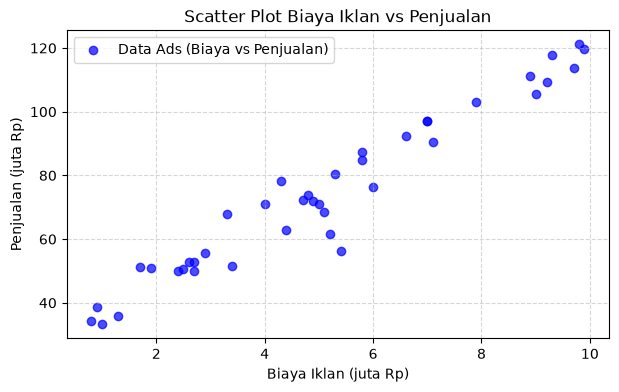

Shape X_train: (32, 1), X_test: (8, 1)
Shape y_train: (32,), y_test: (8,)

Intercept (b): 29.3864
Koefisien (m): 9.0711
Persamaan Regresi: y_hat = 29.3864 + 9.0711 * X


In [7]:
# A1. Scatter Plot
X_ads = ads_df[["BiayaIklan"]].values
y_ads = ads_df["Penjualan"].values

plt.figure(figsize=(7, 4))
plt.scatter(
    X_ads, y_ads, color="blue", alpha=0.7, label="Data Ads (Biaya vs Penjualan)"
)
plt.title("Scatter Plot Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()


# Fungsi train_test_split manual dengan NumPy
def train_test_split(X, y, test_size=0.2, random_state=None):
  if random_state is not None:
    np.random.seed(random_state)
  n_samples = len(X)
  indices = np.arange(n_samples)
  np.random.shuffle(indices)
  test_size_val = int(n_samples * test_size)
  return (
      X[indices[test_size_val:]],
      X[indices[:test_size_val]],
      y[indices[test_size_val:]],
      y[indices[:test_size_val]],
  )


# A2. Split Data
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Shape X_train: {X_train_a.shape}, X_test: {X_test_a.shape}")
print(f"Shape y_train: {y_train_a.shape}, y_test: {y_test_a.shape}\n")


# A3. Normal Equation
class LinearRegressionNormal:

  def fit(self, X, y):
    X_b = np.c_[np.ones((X.shape[0], 1)), X]
    theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
    self.intercept_ = theta[0]
    self.coef_ = theta[1:]

  def predict(self, X):
    X_b = np.c_[np.ones((X.shape[0], 1)), X]
    return X_b.dot(np.r_[self.intercept_, self.coef_])


model_lr_a = LinearRegressionNormal()
model_lr_a.fit(X_train_a, y_train_a)

b_a = model_lr_a.intercept_
m_a = model_lr_a.coef_[0]
print(f"Intercept (b): {b_a:.4f}")
print(f"Koefisien (m): {m_a:.4f}")
print(f"Persamaan Regresi: y_hat = {b_a:.4f} + {m_a:.4f} * X")

Tabel Evaluasi Regresi Linear:
   Metrik  Training   Testing
      MAE  3.792050  7.202294
      MSE 24.440353 87.131626
     RMSE  4.943719  9.334432
R^2 Score  0.961790  0.846418
LR 0.001 -> Intercept: 26.2690, Koefisien: 9.5481
LR 0.02 -> Intercept: 29.3864, Koefisien: 9.0711


c:\Users\azka\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\azka\AppData\Local\Temp\ipykernel_8016\3223802622.py:41: RuntimeWarning: overflow encountered in square
  self.loss_history.append(np.mean(error**2))
C:\Users\azka\AppData\Local\Temp\ipykernel_8016\3223802622.py:39: RuntimeWarning: overflow encountered in dot
  self.coef_ -= (2 / n_samples) * self.lr * X.T.dot(error)
C:\Users\azka\AppData\Local\Temp\ipykernel_8016\3223802622.py:39: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= (2 / n_samples) * self.lr * X.T.dot(error)


LR 0.1 -> Intercept: nan, Koefisien: nan


c:\Users\azka\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


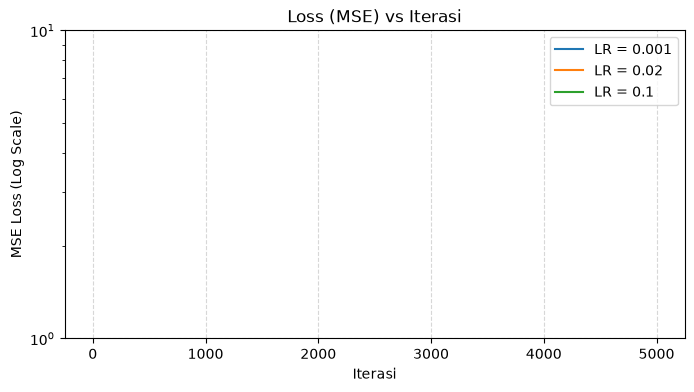

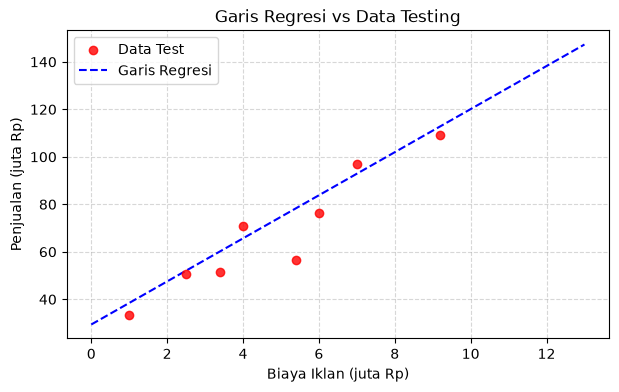

Biaya Iklan 4.5 juta Rp -> Prediksi Penjualan: 70.21 juta Rp
Biaya Iklan 7.0 juta Rp -> Prediksi Penjualan: 92.88 juta Rp
Biaya Iklan 12.0 juta Rp -> Prediksi Penjualan: 138.24 juta Rp


In [8]:
# A4. Evaluasi Model
def evaluate_regression(y_true, y_pred):
  mae = np.mean(np.abs(y_true - y_pred))
  mse = np.mean((y_true - y_pred) ** 2)
  rmse = np.sqrt(mse)
  ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
  ss_res = np.sum((y_true - y_pred) ** 2)
  r2 = 1 - (ss_res / ss_total)
  return mae, mse, rmse, r2


y_tr_pred = model_lr_a.predict(X_train_a)
y_ts_pred = model_lr_a.predict(X_test_a)

df_eval_a = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R^2 Score"],
    "Training": evaluate_regression(y_train_a, y_tr_pred),
    "Testing": evaluate_regression(y_test_a, y_ts_pred),
})
print("Tabel Evaluasi Regresi Linear:")
print(df_eval_a.to_string(index=False))


# A5. Gradient Descent
class LinearRegressionGD:

  def __init__(self, learning_rate=0.02, n_iterations=5000):
    self.lr = learning_rate
    self.n_iter = n_iterations
    self.loss_history = []

  def fit(self, X, y):
    n_samples = X.shape[0]
    self.intercept_ = 0.0
    self.coef_ = np.zeros(X.shape[1])
    for _ in range(self.n_iter):
      y_pred = self.intercept_ + X.dot(self.coef_)
      error = y_pred - y
      self.coef_ -= (2 / n_samples) * self.lr * X.T.dot(error)
      self.intercept_ -= (2 / n_samples) * self.lr * np.sum(error)
      self.loss_history.append(np.mean(error**2))


plt.figure(figsize=(8, 4))
for lr in [0.001, 0.02, 0.1]:
  gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
  gd.fit(X_train_a, y_train_a)
  plt.plot(gd.loss_history, label=f"LR = {lr}")
  print(
      f"LR {lr} -> Intercept: {gd.intercept_:.4f}, Koefisien:"
      f" {gd.coef_[0]:.4f}"
  )

plt.title("Loss (MSE) vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("MSE Loss (Log Scale)")
plt.yscale("log")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

# A6. Visualisasi & Prediksi
plt.figure(figsize=(7, 4))
plt.scatter(
    X_test_a, y_test_a, color="red", label="Data Test", zorder=3, alpha=0.8
)
x_line = np.linspace(0, 13, 100).reshape(-1, 1)
plt.plot(
    x_line,
    model_lr_a.predict(x_line),
    color="blue",
    linestyle="--",
    label="Garis Regresi",
)
plt.title("Garis Regresi vs Data Testing")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

X_new = np.array([[4.5], [7.0], [12.0]])
preds = model_lr_a.predict(X_new)
for val, p in zip([4.5, 7.0, 12.0], preds):
  print(f"Biaya Iklan {val} juta Rp -> Prediksi Penjualan: {p:.2f} juta Rp")

# B. Logistic Regression

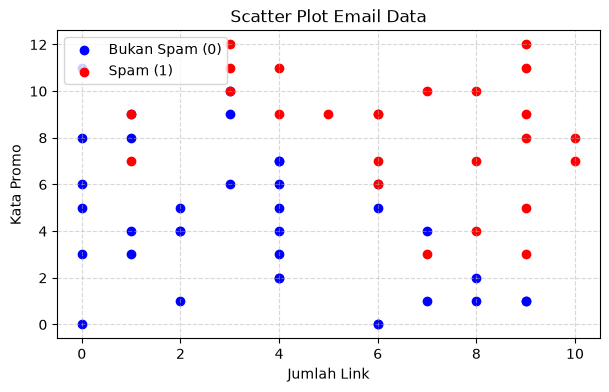

Akurasi: 0.9333, Precision: 1.0000, Recall: 0.9000, F1: 0.9474
Confusion Matrix:
 [[5 0]
 [1 9]]


,Threshold,Precision,Recall,F1-Score,Accuracy
0,0.3,1.0,0.9,0.947368,0.933333
1,0.5,1.0,0.9,0.947368,0.933333
2,0.7,1.0,0.9,0.947368,0.933333


,Email,Probabilitas Spam,Prediksi Kelas
0,E1,0.000223,Bukan Spam
1,E2,0.311677,Bukan Spam
2,E3,0.998914,Spam
3,E4,0.626555,Spam


In [9]:
# B1. Load & Scatter Plot
X_email = email_df[["JumlahLink", "KataPromo"]].values
y_email = email_df["Spam"].values

plt.figure(figsize=(7, 4))
plt.scatter(
    X_email[y_email == 0, 0],
    X_email[y_email == 0, 1],
    color="blue",
    label="Bukan Spam (0)",
)
plt.scatter(
    X_email[y_email == 1, 0],
    X_email[y_email == 1, 1],
    color="red",
    label="Spam (1)",
)
plt.title("Scatter Plot Email Data")
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# B2. Split & Model Training
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)


class LogisticRegressionGD:

  def __init__(self, learning_rate=0.1, n_iterations=10000):
    self.lr = learning_rate
    self.n_iter = n_iterations
    self.loss_history = []

  def _sigmoid(self, z):
    return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

  def fit(self, X, y):
    n_samples, n_features = X.shape
    self.intercept_ = 0.0
    self.coef_ = np.zeros(n_features)
    for _ in range(self.n_iter):
      y_pred = self._sigmoid(self.intercept_ + X.dot(self.coef_))
      self.coef_ -= (1 / n_samples) * self.lr * X.T.dot(y_pred - y)
      self.intercept_ -= (1 / n_samples) * self.lr * np.sum(y_pred - y)
      eps = 1e-15
      y_p = np.clip(y_pred, eps, 1 - eps)
      self.loss_history.append(
          -np.mean(y * np.log(y_p) + (1 - y) * np.log(1 - y_p))
      )

  def predict_proba(self, X):
    return self._sigmoid(self.intercept_ + X.dot(self.coef_))

  def predict(self, X, threshold=0.5):
    return (self.predict_proba(X) >= threshold).astype(int)


model_log = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_log.fit(X_train_b, y_train_b)

# B3. Evaluasi Klasifikasi
def evaluate_classification(y_true, y_pred):
  tp = np.sum((y_true == 1) & (y_pred == 1))
  tn = np.sum((y_true == 0) & (y_pred == 0))
  fp = np.sum((y_true == 0) & (y_pred == 1))
  fn = np.sum((y_true == 1) & (y_pred == 0))
  acc = (tp + tn) / len(y_true)
  prec = tp / (tp + fp) if (tp + fp) > 0 else 0
  rec = tp / (tp + fn) if (tp + fn) > 0 else 0
  f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
  return acc, np.array([[tn, fp], [fn, tp]]), prec, rec, f1


y_pred_b = model_log.predict(X_test_b)
acc_b, cm_b, prec_b, rec_b, f1_b = evaluate_classification(y_test_b, y_pred_b)
print(
    f"Akurasi: {acc_b:.4f}, Precision: {prec_b:.4f}, Recall: {rec_b:.4f},"
    f" F1: {f1_b:.4f}"
)
print("Confusion Matrix:\n", cm_b)

# B5. Variation Threshold
eval_th = []
for th in [0.3, 0.5, 0.7]:
  preds_th = model_log.predict(X_test_b, threshold=th)
  acc, cm, prec, rec, f1 = evaluate_classification(y_test_b, preds_th)
  eval_th.append({
      "Threshold": th,
      "Precision": prec,
      "Recall": rec,
      "F1-Score": f1,
      "Accuracy": acc,
  })
display(pd.DataFrame(eval_th))

# B6. Prediksi Email Baru
new_emails = np.array([[1, 2], [5, 6], [9, 10], [2, 11]])
df_new = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "Probabilitas Spam": model_log.predict_proba(new_emails),
    "Prediksi Kelas": [
        "Spam" if p == 1 else "Bukan Spam"
        for p in model_log.predict(new_emails)
    ],
})
display(df_new)

# C. Pemahaman Konsep

1. **Logistic Regression & Sigmoid:**
   Logistic Regression dinamakan 'regression' karena menghitung kombinasi linear $z = b + m_1 x_1 + m_2 x_2$, namun dikategorikan sebagai 'klasifikasi' karena hasilnya dipetakan oleh fungsi sigmoid ke rentang probabilitas [0, 1] untuk memprediksi kelas diskrit.

2. **Normal Equation vs Gradient Descent:**
   Normal Equation menyelesaikan parameter secara langsung menggunakan rumus matriks analitis tanpa iterasi. Gradient Descent memperbarui bobot secara berulang menuju nilai loss minimum. Gradient Descent lebih unggul pada dataset berukuran sangat besar.

3. **Data Testing & Overfitting:**
   Data testing digunakan untuk mengukur kemampuan generalisasi model pada data baru. Overfitting terjadi ketika model menghafal pola data training dengan sangat detail namun gagal bekerja dengan baik pada data baru.

4. **MSE vs Log Loss:**
   MSE digunakan pada Linear Regression karena outputnya bernilai kontinu. Log Loss digunakan pada Logistic Regression karena mengukur perbedaan antara nilai probabilitas prediksi [0, 1] dengan label biner aktual.

5. **Perbedaan Hasil Angka:**
   Hasil angka berbeda antar mahasiswa karena fungsi `train_test_split` menggunakan `RANDOM_STATE` berbasis 2 digit terakhir NIM masing-masing, sehingga data yang terbagi ke kelompok training dan testing bersifat unik.

# Bonus – Perbandingan dengan scikit-learn

In [10]:
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# Linear Regression
sk_lr = SkLinearRegression()
sk_lr.fit(X_train_a, y_train_a)
print(
    f"Linear Regression (Sklearn) -> Intercept: {sk_lr.intercept_:.4f},"
    f" Koefisien: {sk_lr.coef_[0]:.4f}"
)
print(
    f"Linear Regression (Manual)  -> Intercept: {b_a:.4f}, Koefisien:"
    f" {m_a:.4f}\n"
)

# Logistic Regression
sk_log = SkLogisticRegression(penalty="l2", C=1.0, random_state=RANDOM_STATE)
sk_log.fit(X_train_b, y_train_b)
print(
    f"Logistic Regression (Sklearn) -> Intercept: {sk_log.intercept_[0]:.4f},"
    f" Koefisien: {sk_log.coef_[0]}"
)
print(
    f"Logistic Regression (Manual)  -> Intercept: {model_log.intercept_:.4f},"
    f" Koefisien: {model_log.coef_}"
)

Linear Regression (Sklearn) -> Intercept: 29.3864, Koefisien: 9.0711
Linear Regression (Manual)  -> Intercept: 29.3864, Koefisien: 9.0711

Logistic Regression (Sklearn) -> Intercept: -10.4979, Koefisien: [0.95367177 0.82417556]
Logistic Regression (Manual)  -> Intercept: -11.1911, Koefisien: [1.02640651 0.87779514]


c:\Users\azka\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
